# Linear regression 

**Goal.** Estimate how a stock moves with the market, that is, find the *beta* of the stock (interpreted as market, or systematic risk). 

**Data: stock vs. market returns.** This is Capital Asset Pricing Model (CAPM) used in finance

$$ r^{\text{stock}}_t = \alpha + \beta \, r^{\text{market}}_t + \varepsilon_t $$

* $\beta$ = sensitivity of the stock to the market ($\beta>1$: amplifies market moves, $\beta<1$: dampens them)
* $\alpha$ = average return not explained by the market
* $\sigma$ = size of the stock-specific (idiosyncratic) noise


**Data in this notebook.** `stock_market_prices.xlsx` contains **simulated** month-end prices (60 months) so that the true parameters are known ($\alpha=0.002,\ \beta=1.3,\ \sigma=0.03$) and you can check that the method recovers them (up to sampling error: with only 60 points the estimates will not match exactly). The last section shows how to replace it with real prices.

**Steps**
1. Load the Excel data into pandas
2. Compute returns from prices
3. Formulate the model
4. Write the likelihood and the negative log-likelihood
5. Minimize it with Nelder–Mead
6. Check against the closed-form (normal equations) solution
7. Vizualize likelihood surface


## Step 0 – Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.optimize as so
from scipy import stats

np.set_printoptions(precision=6, suppress=True)

## Step 1 – Load data

`pd.read_excel` reads a sheet into a DataFrame. The file needs the columns `Date`, `Market_Index` and `Stock_Price` on the sheet `Prices` (this needs the `openpyxl` package, which pandas uses to read `.xlsx`). The notebook and the Excel file must be in the same folder.

In [2]:
df = pd.read_excel("stock_market_prices.xlsx", sheet_name="Prices", parse_dates=["Date"])
df = df.sort_values("Date").reset_index(drop=True)
print(df.shape)
df.head()

(61, 3)


,Date,Market_Index,Stock_Price
0,2021-01-31,4000.00,150.00
1,2021-02-28,3914.68,149.95
2,2021-03-31,3915.22,153.25
3,2021-04-30,4239.66,174.94
4,2021-05-31,4399.33,184.76


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61 entries, 0 to 60
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Date          61 non-null     datetime64[ns]
 1   Market_Index  61 non-null     float64       
 2   Stock_Price   61 non-null     float64       
dtypes: datetime64[ns](1), float64(2)
memory usage: 1.6 KB


## Step 2 – Compute returns from prices

Regression is done on **returns**, not prices (prices are not comparable across assets). The simple monthly return is

$$ r_t = \frac{P_t - P_{t-1}}{P_{t-1}} = \frac{P_t}{P_{t-1}} - 1 .$$

We define $x_t$ = market return (explanatory variable) and $y_t$ = stock return (response). The first row has no previous price, so it is dropped.

number of observations: 60
mean / std of market return: 0.0041 0.0445
mean / std of stock return : 0.008 0.0655


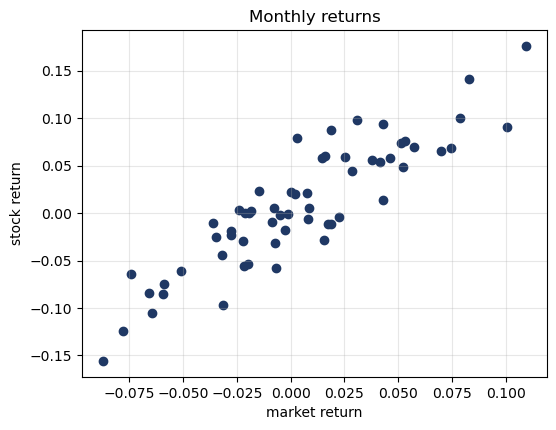

In [4]:
df["Market_Return"] = df["Market_Index"].pct_change()
df["Stock_Return"]  = df["Stock_Price"].pct_change()
df = df.dropna().reset_index(drop=True)

x = df["Market_Return"].to_numpy()   # explanatory variable
y = df["Stock_Return"].to_numpy()    # response
n = len(x)
print("number of observations:", n)
print("mean / std of market return:", x.mean().round(4), x.std(ddof=1).round(4))
print("mean / std of stock return :", y.mean().round(4), y.std(ddof=1).round(4))

plt.figure(figsize=(6, 4.5))
plt.scatter(x, y, color="#1F3864")
plt.xlabel("market return"); plt.ylabel("stock return")
plt.title("Monthly returns"); plt.grid(alpha=0.3); plt.show()

## Step 3 – The model

We assume each stock return is a straight line in the market return plus independent Gaussian noise:

$$ y_t = \alpha + \beta\, x_t + \varepsilon_t, \qquad \varepsilon_t \sim \mathcal N(0,\sigma^2), \quad t=1,\dots,n .$$

Equivalently, each observation is normally distributed around the line:

$$ y_t \mid x_t \;\sim\; \mathcal N\!\left(\alpha+\beta x_t,\ \sigma^2\right). $$

The unknown parameter vector is $\theta = (\alpha,\beta,\sigma)$.

## Step 4 – The likelihood and the negative log-likelihood

The density of one observation is

$$ f(y_t \mid x_t;\theta) = \frac{1}{\sqrt{2\pi\sigma^2}}\exp\!\left(-\frac{(y_t-\alpha-\beta x_t)^2}{2\sigma^2}\right). $$

Observations are independent, so the likelihood of the whole sample is the product

$$ L(\theta)=\prod_{t=1}^{n} f(y_t\mid x_t;\theta). $$

Taking logs turns the product into a sum (easier to differentiate, and numerically safe):

$$ \ell(\theta)=\ln L(\theta) = -\frac{n}{2}\ln(2\pi) - n\ln\sigma - \frac{1}{2\sigma^2}\sum_{t=1}^{n}(y_t-\alpha-\beta x_t)^2 . $$

The maximum likelihood estimate is $\hat\theta=\arg\max_\theta \ell(\theta)$. Optimizers in SciPy **minimize**, so we minimize

$$ \text{NLL}(\theta) = -\ell(\theta). $$

**Parametrization trick.** $\sigma$ must be positive, but we do not want to require this through a constraint to optimization method.. We optimize over $s=\ln\sigma$ and set $\sigma=e^{s}$, which is positive for every real $s$. The optimizer works with $(\alpha,\beta,s)$.

**Observation.** For fixed $\sigma$, only the last term depends on $(\alpha,\beta)$: maximizing $\ell$ over $(\alpha,\beta)$ is the same as minimizing the sum of squared errors – **MLE with Gaussian noise equals least squares.**

In [5]:
def nll(theta, x, y):
    """Negative log-likelihood of the Gaussian linear regression model.
    theta = (alpha, beta, log_sigma)."""
    alpha, beta, log_sigma = theta
    sigma = np.exp(log_sigma)
    resid = y - (alpha + beta * x)
    n = len(y)
    return 0.5 * n * np.log(2 * np.pi) + n * log_sigma + np.sum(resid**2) / (2 * sigma**2)

# quick check: the NLL is lower for parameters close to the truth than for poor ones
print(nll([0.002, 1.3, np.log(0.03)], x, y))   # near the data-generating values
print(nll([0.0,   0.0, np.log(0.03)], x, y))   # a flat line - much worse

-126.54919331598052
-12.546666390201352


## Step 5 – Solve the MLE problem with Nelder–Mead

**Nelder–Mead** (downhill simplex) is a derivative-free method: it keeps $n+1$ points in $n$ dimensions (a triangle for 2 parameters, a tetrahedron for 3), and repeatedly reflects, expands, contracts or shrinks the simplex using only comparisons of function values.

We need a **starting point** $\theta_0$. Reasonable choices: $\alpha_0=0$, $\beta_0=1$, and $\sigma_0$ = standard deviation of $y$. We also tighten the tolerances (`xatol`, `fatol`): returns are small numbers (about 0.01–0.05), and the default tolerances can stop too early.

In [6]:
theta0 = np.array([0.0, 1.0, np.log(y.std())])

res_nm = so.minimize(nll, theta0, args=(x, y), method="Nelder-Mead",
                     options={"xatol": 1e-10, "fatol": 1e-12, "maxiter": 10000, "maxfev": 10000})

alpha_mle, beta_mle, sigma_mle = res_nm.x[0], res_nm.x[1], np.exp(res_nm.x[2])
print(res_nm.message)
print("iterations:", res_nm.nit, "  function evaluations:", res_nm.nfev)
print(f"alpha_hat = {alpha_mle:.6f}")
print(f"beta_hat  = {beta_mle:.6f}")
print(f"sigma_hat = {sigma_mle:.6f}")
print(f"NLL at optimum = {res_nm.fun:.4f}")

Optimization terminated successfully.
iterations: 132   function evaluations: 260
alpha_hat = 0.002578
beta_hat  = 1.312291
sigma_hat = 0.029335
NLL at optimum = -126.6019


## Step 6 – Check against the closed-form solution

For this model the MLE can also be found by hand. Setting $\partial\ell/\partial\alpha=0$ and $\partial\ell/\partial\beta=0$ gives the **normal equations**, with solution

$$ \hat\beta=\frac{\sum_t (x_t-\bar x)(y_t-\bar y)}{\sum_t (x_t-\bar x)^2}=\frac{S_{xy}}{S_{xx}}, \qquad \hat\alpha=\bar y-\hat\beta\,\bar x, $$

and setting $\partial\ell/\partial\sigma=0$ gives

$$ \hat\sigma^2=\frac{1}{n}\sum_t (y_t-\hat\alpha-\hat\beta x_t)^2 = \frac{\text{SSE}}{n}. $$

(The MLE divides by $n$, not $n-2$, so it is slightly biased downward in small samples.) A numerical optimizer must reproduce these numbers – a very useful test of the code.

In [7]:
Sxy = np.sum((x - x.mean()) * (y - y.mean()))
Sxx = np.sum((x - x.mean())**2)
beta_cf  = Sxy / Sxx
alpha_cf = y.mean() - beta_cf * x.mean()
sse = np.sum((y - alpha_cf - beta_cf * x)**2)
sigma_cf = np.sqrt(sse / n)

cmp = pd.DataFrame({"closed form": [alpha_cf, beta_cf, sigma_cf],
                    "Nelder-Mead MLE": [alpha_mle, beta_mle, sigma_mle],
                    "true (simulation)": [0.002, 1.3, 0.03]},
                   index=["alpha", "beta", "sigma"])
cmp["abs. difference"] = (cmp["closed form"] - cmp["Nelder-Mead MLE"]).abs()
cmp

,closed form,Nelder-Mead MLE,true (simulation),abs. difference
alpha,0.002578,0.002578,0.002,1.561891e-10
beta,1.312291,1.312291,1.300,8.310127e-09
sigma,0.029335,0.029335,0.030,1.566090e-10


### Visualizing the likelihood surface

Fix $\alpha=\hat\alpha$ and $\sigma=\hat\sigma$ and look at the NLL as a function of $\beta$ only. The minimum of this curve is the MLE, and its width reflects the standard error found in Step 8.

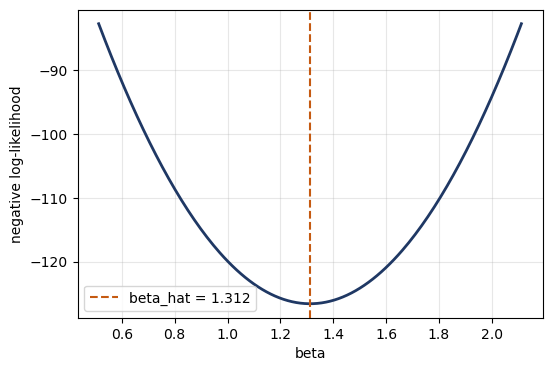

In [8]:
betas = np.linspace(beta_mle - 0.8, beta_mle + 0.8, 200)
curve = [nll([alpha_mle, b, np.log(sigma_mle)], x, y) for b in betas]
plt.figure(figsize=(6, 4))
plt.plot(betas, curve, color="#1F3864", lw=2)
plt.axvline(beta_mle, color="#C55A11", ls="--", label=f"beta_hat = {beta_mle:.3f}")
plt.xlabel("beta"); plt.ylabel("negative log-likelihood"); plt.legend(); plt.grid(alpha=0.3); plt.show()

## Interpretation

* $\hat\beta$ is the estimated market sensitivity: when the market moves by 1 %, the stock moves by about $\hat\beta$ % on average.
* $\hat\alpha$ is the average monthly return unexplained by the market.
* $\hat\sigma$ is the monthly stock-specific risk that cannot be explained by the market.
* The numerical MLE (Nelder–Mead and other optimizers) agrees with the closed-form least-squares solution, which confirms that **maximum likelihood with Gaussian noise = least squares**. The optimization route matters because it keeps working for models with no closed form (logistic regression, heavy-tailed noise, neural networks).

**Exercise**
1. Replace the Gaussian noise by Student-$t$ noise (heavy tails, more realistic for returns): write the new NLL and re-run Step 5.
2. Use *excess* returns (subtract a risk-free rate) to get the proper CAPM regression.
3. Add a second explanatory variable (e.g. a sector index) and extend $\theta$.

# Part II – MAP estimation. Adding prior knowledge about parametr distribution

## Step 8 – From MLE to MAP

So far $\theta=(\alpha,\beta,\sigma)$ was an unknown constant and **only the data** decided the estimate. In the Bayesian view we also write down what we believe *before* seeing the data as a **prior** $p(\theta)$. Bayes' rule combines it with the likelihood into the **posterior**

$$ p(\theta\mid \text{data}) = \frac{L(\theta)\,p(\theta)}{p(\text{data})} \;\propto\; L(\theta)\,p(\theta). $$

The **maximum a posteriori (MAP)** estimate is the mode of the posterior. The denominator does not depend on $\theta$, so it drops out when we maximize:

$$ \hat\theta_{\text{MAP}}=\arg\max_\theta\big[\ell(\theta)+\ln p(\theta)\big]=\arg\min_\theta\big[\text{NLL}(\theta)-\ln p(\theta)\big]. $$

MAP is the NLL from Step 4 **plus a penalty coming from the prior**. With a flat prior ($p(\theta)=$ const) the penalty vanishes and MAP = MLE.

**What do we know before looking at this stock's returns?**

* $\beta$: the market portfolio has beta 1 by construction, so the average stock has $\beta\approx 1$ and most stocks lie roughly in $[0.5,1.5]$. Prior: $\beta\sim\mathcal N(\beta_0=1,\ \tau_\beta^2)$ with $\tau_\beta=0.25$ (about 95 % of the prior mass in $[0.5,1.5]$).
* $\alpha$: in an efficient market CAPM says $\alpha=0$, and monthly alphas are small. Prior: $\alpha\sim\mathcal N(0,\ \tau_\alpha^2)$ with $\tau_\alpha=0.01$ (95 % within $\pm 2\%$ per month).
* $\sigma$: no strong view, so we use a flat prior on $s=\ln\sigma$ (it adds nothing to the objective).

For Gaussian priors, $-\ln p(\theta)$ is a quadratic penalty (constants dropped):

$$ -\ln p(\theta) = \frac{(\alpha-\alpha_0)^2}{2\tau_\alpha^2}+\frac{(\beta-\beta_0)^2}{2\tau_\beta^2}+\text{const}, \qquad \text{so}\qquad \text{NLP}(\theta)=\text{NLL}(\theta)+\frac{(\alpha-\alpha_0)^2}{2\tau_\alpha^2}+\frac{(\beta-\beta_0)^2}{2\tau_\beta^2}. $$

This is **ridge regression that shrinks towards the prior mean** $(\alpha_0,\beta_0)$ instead of towards zero; for known $\sigma$ the equivalent ridge penalty is $\lambda_\beta=\sigma^2/\tau_\beta^2$. (A Laplace prior would give the LASSO, an $L_1$ penalty.) Regularization is the Bayesian prior in disguise.

**Closed form.** With $X=[\mathbf 1,\ x]$, prior mean $m=(\alpha_0,\beta_0)^\top$ and prior precision $\Lambda=\text{diag}(1/\tau_\alpha^2,\,1/\tau_\beta^2)$, setting the gradient to zero for fixed $\sigma$ gives

$$ \begin{pmatrix}\hat\alpha\\ \hat\beta\end{pmatrix}_{\text{MAP}}=\Big(\tfrac{1}{\sigma^2}X^\top X+\Lambda\Big)^{-1}\Big(\tfrac{1}{\sigma^2}X^\top y+\Lambda m\Big), $$

a **precision-weighted average** of the least-squares solution and the prior mean. The more informative the data (large $X^\top X/\sigma^2$), the less the prior matters. For $\sigma$ we get $\hat\sigma^2_{\text{MAP}}=\text{SSE}(\hat\alpha_{\text{MAP}},\hat\beta_{\text{MAP}})/n$ from $\partial/\partial s=0$.

**A caveat.** MAP is *not* invariant to reparametrization: "flat in $\sigma$" and "flat in $\ln\sigma$" are different priors and give different modes for $\sigma$. The MLE does not have this problem.

In [ ]:
# Prior hyper-parameters (our "prior knowledge")
alpha0, tau_alpha = 0.0, 0.01     # alpha ~ N(0, 0.01^2): CAPM says alpha is about 0
beta0,  tau_beta  = 1.0, 0.25     # beta  ~ N(1, 0.25^2): the average stock has beta = 1
# sigma: flat prior on log(sigma) -> contributes nothing to the objective

def neg_log_prior(theta, tau_alpha=tau_alpha, tau_beta=tau_beta):
    # -ln p(theta) up to a constant. theta = (alpha, beta, log_sigma)
    alpha, beta, _ = theta
    return (alpha - alpha0)**2 / (2 * tau_alpha**2) + (beta - beta0)**2 / (2 * tau_beta**2)

def neg_log_posterior(theta, x, y, tau_alpha=tau_alpha, tau_beta=tau_beta):
    # NLP = NLL (Step 4) + penalty from the prior
    return nll(theta, x, y) + neg_log_prior(theta, tau_alpha, tau_beta)

# sanity check: the prior pulls the objective towards (alpha0, beta0)
print("NLL at MLE      :", nll(res_nm.x, x, y))
print("NLP at MLE      :", neg_log_posterior(res_nm.x, x, y))

## Step 9 – Solve the MAP problem and check it

Same recipe as Step 5: Nelder–Mead on the new objective. Then we verify the answer with the closed-form precision-weighted formula (plugging in the optimizer's $\hat\sigma_{\text{MAP}}$).

In [ ]:
res_map = so.minimize(neg_log_posterior, theta0, args=(x, y), method="Nelder-Mead",
                      options={"xatol": 1e-10, "fatol": 1e-12, "maxiter": 10000, "maxfev": 10000})
alpha_map, beta_map, sigma_map = res_map.x[0], res_map.x[1], np.exp(res_map.x[2])
print(res_map.message)

# closed form for (alpha, beta) given sigma_map
X   = np.column_stack([np.ones(n), x])
Lam = np.diag([1 / tau_alpha**2, 1 / tau_beta**2])
m   = np.array([alpha0, beta0])
alpha_cf_map, beta_cf_map = np.linalg.solve(X.T @ X / sigma_map**2 + Lam,
                                            X.T @ y / sigma_map**2 + Lam @ m)
# closed form for sigma given the MAP line
sigma_cf_map = np.sqrt(np.sum((y - alpha_map - beta_map * x)**2) / n)

cmp_map = pd.DataFrame({"MLE": [alpha_mle, beta_mle, sigma_mle],
                        "MAP (Nelder-Mead)": [alpha_map, beta_map, sigma_map],
                        "MAP (closed form)": [alpha_cf_map, beta_cf_map, sigma_cf_map],
                        "prior mean": [alpha0, beta0, np.nan],
                        "true (simulation)": [0.002, 1.3, 0.03]},
                       index=["alpha", "beta", "sigma"])
cmp_map["|NM - closed form|"] = (cmp_map["MAP (Nelder-Mead)"] - cmp_map["MAP (closed form)"]).abs()
cmp_map

**Reading the table.** The MAP estimates sit *between* the MLE and the prior mean: $\hat\beta_{\text{MAP}}$ is pulled towards 1 and $\hat\alpha_{\text{MAP}}$ towards 0. The last column should be about $10^{-8}$ or smaller (numerical optimizer = closed form).

Note that the prior here ($\beta_0=1$) is deliberately *not* centred on the simulation truth ($\beta=1.3$), as a real prior never is. The next steps show when this helps and when it costs you.

## Step 10 – Prior × likelihood = posterior

Look at one parameter at a time: fix $\alpha$ and $\sigma$ at their MAP values and plot, as functions of $\beta$, the (normalized) likelihood, the prior and the posterior. Because the posterior is the product of the two curves, its peak lies between them – closer to whichever is *narrower* (more informative).

In [ ]:
bgrid = np.linspace(0.2, 2.2, 800)
db = bgrid[1] - bgrid[0]

log_lik   = -np.array([nll([alpha_map, b, np.log(sigma_map)], x, y) for b in bgrid])
log_prior = -(bgrid - beta0)**2 / (2 * tau_beta**2)
log_post  = log_lik + log_prior

def to_density(logf):
    f = np.exp(logf - logf.max())
    return f / (f.sum() * db)          # normalize to area 1 so the curves are comparable

plt.figure(figsize=(7, 4.5))
plt.plot(bgrid, to_density(log_lik),   color="#1F3864", lw=2, label="likelihood (data)")
plt.plot(bgrid, to_density(log_prior), color="#7F7F7F", lw=2, label=f"prior  N({beta0}, {tau_beta}$^2$)")
plt.plot(bgrid, to_density(log_post),  color="#C55A11", lw=2.5, label="posterior ∝ likelihood × prior")
plt.axvline(bgrid[np.argmax(log_lik)],  color="#1F3864", ls=":",  lw=1)
plt.axvline(beta_map,                   color="#C55A11", ls="--", lw=1, label=f"beta_MAP = {beta_map:.3f}")
plt.axvline(1.3, color="green", ls=":", lw=1.5, label="true beta (simulation)")
plt.xlabel("beta"); plt.ylabel("density (alpha, sigma fixed at MAP values)")
plt.title("Prior, likelihood and posterior for beta"); plt.legend(); plt.grid(alpha=0.3); plt.show()

# precision (1/variance) of the two sources of information about beta
w = to_density(log_lik) * db                      # likelihood curve as weights summing to 1
var_lik    = np.sum(w * bgrid**2) - np.sum(w * bgrid)**2
prec_lik   = 1 / var_lik
prec_prior = 1 / tau_beta**2
print(f"precision of data about beta : {prec_lik:8.1f}   (sd = {prec_lik**-0.5:.3f})")
print(f"precision of the prior       : {prec_prior:8.1f}   (sd = {tau_beta:.3f})")
print(f"weight of the prior in the posterior mean: {prec_prior / (prec_lik + prec_prior):.1%}")

For Gaussian curves the posterior mean is exactly the precision-weighted average of the likelihood peak and the prior mean, and the printed weights tell you how much the prior contributes. With 60 observations the data are fairly informative, so the prior moves the estimate only moderately.

## Step 11 – How strong should the prior be?

Two experiments show the trade-off.

**(a) Prior width $\tau_\beta$.** $\tau_\beta\to\infty$ is a flat prior ($\hat\beta_{\text{MAP}}\to\hat\beta_{\text{MLE}}$); $\tau_\beta\to 0$ is a dogmatic prior ($\hat\beta_{\text{MAP}}\to\beta_0$).

**(b) Sample size.** Pretend we only have the first $k$ months of history (a newly listed stock). The likelihood is a sum of $k$ terms that grows with the data, while the prior is a fixed penalty, so the prior should matter a lot for small $k$ and fade as $k$ grows.

In [ ]:
# (a) shrinkage path: beta_MAP as a function of the prior width tau_beta
taus = np.logspace(-2.5, 0.5, 30)
beta_path = []
for t in taus:
    r = so.minimize(neg_log_posterior, res_nm.x, args=(x, y, tau_alpha, t), method="Nelder-Mead",
                    options={"xatol": 1e-10, "fatol": 1e-12, "maxiter": 10000, "maxfev": 10000})
    beta_path.append(r.x[1])

plt.figure(figsize=(7, 4.5))
plt.semilogx(taus, beta_path, color="#C55A11", lw=2.5, label="beta_MAP")
plt.axhline(beta_mle, color="#1F3864", ls="--", label=f"beta_MLE = {beta_mle:.3f}")
plt.axhline(beta0,    color="#7F7F7F", ls="--", label=f"prior mean = {beta0}")
plt.axvline(tau_beta, color="k", ls=":", lw=1, label=f"our choice tau_beta = {tau_beta}")
plt.xlabel("prior standard deviation tau_beta (log scale)"); plt.ylabel("beta")
plt.title("Shrinkage: from the prior mean to the MLE"); plt.legend(); plt.grid(alpha=0.3); plt.show()

In [ ]:
# (b) the same estimators on the first k months only
fit_opts = {"xatol": 1e-10, "fatol": 1e-12, "maxiter": 10000, "maxfev": 10000}
rows = []
for k in [5, 10, 20, 40, n]:
    xk, yk = x[:k], y[:k]
    t0 = np.array([0.0, 1.0, np.log(yk.std())])
    b_mle = so.minimize(nll,                 t0, args=(xk, yk), method="Nelder-Mead", options=fit_opts).x[1]
    b_map = so.minimize(neg_log_posterior,   t0, args=(xk, yk), method="Nelder-Mead", options=fit_opts).x[1]
    rows.append({"months of data k": k, "beta MLE": b_mle, "beta MAP": b_map, "|MAP - MLE|": abs(b_map - b_mle)})
pd.DataFrame(rows).set_index("months of data k").round(4)

**What you should see.**

* In (a) the curve moves monotonically from the prior mean (tight prior) to the MLE (wide prior). The choice of $\tau_\beta$ is a modelling decision: it states how sure you are *before* seeing the data.
* In (b) the gap $|\hat\beta_{\text{MAP}}-\hat\beta_{\text{MLE}}|$ is largest for few observations and shrinks as $k$ grows: **with enough data the prior is overwhelmed and MAP ≈ MLE.** With very few points the MLE is noisy, and a sensible prior stabilizes it (lower variance) at the price of some bias if the prior is off. Here the prior mean (1.0) is below the simulation truth (1.3), so for small $k$ MAP can be *worse* than the MLE in a given sample; the gain is on average over samples, when the prior is reasonable.
* Only the first $k$ months are used in (b), so individual rows are noisy and need not be perfectly monotone; the trend is what matters.

---

# Part III – When the errors are not Gaussian

## Step 12 – Outliers and the shape of the error distribution

Gaussian errors have very light tails: a residual beyond $5\sigma$ should happen about once in 1.7 million observations. Real stock returns do not behave like that – earnings surprises, take-over bids, lawsuits and crashes produce occasional huge stock-specific moves. These shocks are *not* explained by the market, so they show up as **vertical outliers** in $y$.

We contaminate the data we have: three of the 60 months get an extra stock-specific shock – $-8\hat\sigma$ and $-6\hat\sigma$ in the two strongest market months (the stock crashes on good market days) and $+7\hat\sigma$ in the weakest market month (about $\pm 20\%$ with the simulated numbers). Everything else stays the same, so any change in the fit is caused by those three points. The shocks are placed at the market extremes on purpose: that is where a line is most easily tilted. They are still *vertical* outliers – the market returns themselves are untouched.

In [ ]:
# --- contaminate three months with large stock-specific shocks ---------------------------------
# Stock-specific shocks that coincide with the most extreme market months:
# crashes in the two strongest up-months and a spike in the weakest month (e.g. company news on a big market day).
order   = np.argsort(x)
out_idx = np.array([order[-1], order[-2], order[0]])
shock   = np.array([-8.0, -6.0, 7.0]) * sigma_mle
y_out   = y.copy()
y_out[out_idx] += shock
is_out  = np.zeros(n, dtype=bool); is_out[out_idx] = True
print("outlier months:", out_idx, "  market returns:", x[out_idx].round(3), "  shocks:", shock.round(3))

# --- Gaussian MLE = least squares (closed form from Step 6), as a reusable function -------------
def fit_gaussian(x, y):
    beta  = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean())**2)
    alpha = y.mean() - beta * x.mean()
    resid = y - alpha - beta * x
    return alpha, beta, np.sqrt(np.mean(resid**2)), resid

a_c, b_c, s_c, res_c = fit_gaussian(x, y)        # clean data
a_o, b_o, s_o, res_o = fit_gaussian(x, y_out)    # contaminated data

summary = pd.DataFrame({"clean": [a_c, b_c, s_c, stats.kurtosis(res_c), stats.shapiro(res_c).pvalue],
                        "with 3 outliers": [a_o, b_o, s_o, stats.kurtosis(res_o), stats.shapiro(res_o).pvalue]},
                       index=["alpha_hat", "beta_hat", "sigma_hat", "excess kurtosis of residuals", "Shapiro-Wilk p-value"])
print(summary.round(4))

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))

# (a) data and the two least-squares lines
xx = np.linspace(x.min(), x.max(), 100)
ax[0].scatter(x[~is_out], y_out[~is_out], color="#1F3864", label="regular months")
ax[0].scatter(x[is_out], y_out[is_out], color="red", s=70, zorder=3, label="outliers")
ax[0].scatter(x[is_out], y[is_out], facecolors="none", edgecolors="red", alpha=0.5, label="same months before shock")
ax[0].plot(xx, a_c + b_c * xx, color="#7F7F7F", ls="--", lw=2, label=f"OLS clean: beta={b_c:.2f}")
ax[0].plot(xx, a_o + b_o * xx, color="#C55A11", lw=2, label=f"OLS with outliers: beta={b_o:.2f}")
ax[0].set_xlabel("market return"); ax[0].set_ylabel("stock return"); ax[0].set_title("Least squares is pulled by 3 points")
ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)

# (b),(c) residual distribution vs. the fitted normal density
bins = np.linspace(-0.2, 0.2, 33)
grid = np.linspace(-0.2, 0.2, 400)
for a_, r_, s_, ttl in [(ax[1], res_c, s_c, "Residuals, clean data"),
                        (ax[2], res_o, s_o, "Residuals, with 3 outliers")]:
    a_.hist(r_, bins=bins, density=True, color="#9DB4D9", edgecolor="white")
    a_.plot(grid, stats.norm.pdf(grid, 0, s_), color="#C55A11", lw=2.5, label=f"fitted normal, sigma_hat={s_:.3f}")
    a_.set_xlabel("residual"); a_.set_title(ttl); a_.legend(fontsize=8); a_.grid(alpha=0.3)
top = max(ax[1].get_ylim()[1], ax[2].get_ylim()[1])
ax[1].set_ylim(0, top); ax[2].set_ylim(0, top); ax[1].set_ylabel("density")
plt.tight_layout(); plt.show()

**What happens to the error distribution.**

* **The line moves.** Three points out of 60 change $\hat\beta$ (and $\hat\alpha$) noticeably, because the squared error is dominated by the largest residuals.
* **$\hat\sigma$ inflates.** The fitted normal becomes much wider to "cover" the outliers, so it is too wide for the bulk of the data (the histogram peak is far above the curve) and *still* assigns almost no probability to the outliers themselves. A Gaussian cannot describe "mostly small errors, occasionally huge ones".
* **Diagnostics notice it.** Excess kurtosis (0 for a normal) jumps well above zero and the Shapiro–Wilk test rejects normality, whereas for the clean data it should not.

The problem is not the optimizer: least squares *is* the MLE of the Gaussian model, so the assumption itself is wrong. If the assumed error density is wrong, we should change the density.

## Step 13 – The error density *is* the loss function

Let the errors have a general density, $\varepsilon_t=\sigma u_t$ with $u_t\sim f$. Then, with $r_t=y_t-\alpha-\beta x_t$,

$$ \text{NLL}(\theta)=n\ln\sigma+\sum_{t=1}^n \rho\!\left(\frac{r_t}{\sigma}\right), \qquad \rho(u)=-\ln f(u). $$

So the MLE minimizes a sum of a **loss function** $\rho$ of the residuals; each error distribution defines one. The derivative $\psi=\rho'$ is the **influence function**: the score equation for $\beta$ is $\sum_t \psi(r_t/\sigma)\,x_t=0$, i.e. $\psi$ is how hard a residual of a given size pulls on the fitted line.

| Error distribution | $f(u)\propto$ | loss $\rho(u)$ | MLE of the line | influence $\psi(u)$ |
|---|---|---|---|---|
| Gaussian | $e^{-u^2/2}$ | $u^2/2$ | least squares (conditional **mean**) | $u$ – grows without bound |
| Laplace | $e^{-\lvert u\rvert}$ | $\lvert u\rvert$ | least absolute deviations (conditional **median**) | $\text{sign}(u)$ – bounded |
| Student-$t_\nu$ | $(1+u^2/\nu)^{-(\nu+1)/2}$ | $\tfrac{\nu+1}{2}\ln(1+u^2/\nu)$ | robust M-estimator | $\tfrac{(\nu+1)u}{\nu+u^2}$ – rises, then **falls** back towards 0 |

(The densities are written without normalizing constants; the exact ones are coded in Step 14. Shapes are what matter here.)

In [ ]:
u  = np.linspace(-8, 8, 801)
nu = 3

rho_gauss   = u**2 / 2
rho_laplace = np.abs(u)
rho_t       = (nu + 1) / 2 * np.log1p(u**2 / nu)

psi_gauss   = u
psi_laplace = np.sign(u)
psi_t       = (nu + 1) * u / (nu + u**2)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for rho, psi, c, lab in [(rho_gauss, psi_gauss, "#1F3864", "Gaussian  (squared loss)"),
                         (rho_laplace, psi_laplace, "#2E8B57", "Laplace  (absolute loss)"),
                         (rho_t, psi_t, "#C55A11", f"Student-t, nu={nu}")]:
    ax[0].plot(u, rho, color=c, lw=2.2, label=lab)
    ax[1].plot(u, psi, color=c, lw=2.2, label=lab)
ax[0].set_ylim(0, 12); ax[0].set_xlabel("standardized residual u = r / sigma"); ax[0].set_ylabel("loss  rho(u) = -ln f(u)")
ax[0].set_title("What each error model charges for a residual"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].set_ylim(-5, 5); ax[1].set_xlabel("standardized residual u = r / sigma"); ax[1].set_ylabel("influence  psi(u) = rho'(u)")
ax[1].set_title("How hard a residual pulls on the fitted line"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

Compare the two panels at $u=7$ (our outliers): the Gaussian charges $7^2/2\approx 24$ and pulls with force 7, so the optimizer will move the line to shrink that residual. The Laplace charge is only 7, with constant force 1. The Student-$t$ charge grows only logarithmically and its pull is *decreasing* – a very far point is treated almost as a lost cause and ignored.

## Step 14 – MLE with Laplace and Student-$t$ errors

**Laplace** (double exponential) with scale $b$: $f(r)=\frac{1}{2b}e^{-|r|/b}$, so

$$ \text{NLL}=n\ln(2b)+\frac1b\sum_t|r_t|. $$

For fixed $b$ the line minimizes $\sum_t|r_t|$ (median regression) and then $\hat b=\frac1n\sum_t|\hat r_t|$. This objective has kinks, so Nelder–Mead is only approximately right; we verify it with the exact **linear-programming** solution of least absolute deviations.

**Student-$t$** with location–scale parametrization $(\sigma,\nu)$:

$$ f(r)=\frac{\Gamma\!\big(\tfrac{\nu+1}{2}\big)}{\Gamma\!\big(\tfrac{\nu}{2}\big)\sqrt{\nu\pi}\,\sigma}\left(1+\frac{r^2}{\nu\sigma^2}\right)^{-\frac{\nu+1}{2}}, \qquad \text{NLL}=-\sum_t\ln f(r_t). $$

There is **no closed form**, which is the point made at the end of the original notebook. We let the data decide the tail heaviness $\nu$ too (small $\nu$ = heavy tails, $\nu\to\infty$ = Gaussian). As in Step 4 we optimize over logs, $\ln\sigma$ and $\ln\nu$, to keep them positive; and we cap $\nu\le 200$ because for light tails the likelihood becomes flat in $\nu$ and the optimizer would otherwise drift.

In [ ]:
from scipy.special import gammaln
from scipy.optimize import linprog

def nll_laplace(theta, x, y):
    # theta = (alpha, beta, log_b)
    alpha, beta, log_b = theta
    b = np.exp(log_b)
    resid = y - (alpha + beta * x)
    return len(y) * np.log(2 * b) + np.sum(np.abs(resid)) / b

def nll_student(theta, x, y):
    # theta = (alpha, beta, log_sigma, log_nu)
    alpha, beta, log_sigma, log_nu = theta
    sigma, nu = np.exp(log_sigma), np.exp(log_nu)
    uu = (y - (alpha + beta * x)) / sigma
    n_ = len(y)
    return -(n_ * (gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(nu * np.pi) - log_sigma)
             - (nu + 1) / 2 * np.sum(np.log1p(uu**2 / nu)))

# --- unit tests against scipy's own densities (same trick as the closed-form check in Step 6) ---
th_l = np.array([0.001, 1.2, np.log(0.03)])
th_t = np.array([0.001, 1.2, np.log(0.03), np.log(4.0)])
r_l = y - th_l[0] - th_l[1] * x
print("Laplace  NLL:", nll_laplace(th_l, x, y), " scipy:", -stats.laplace.logpdf(r_l, scale=0.03).sum())
print("Student  NLL:", nll_student(th_t, x, y), " scipy:", -stats.t.logpdf(r_l, df=4, scale=0.03).sum())

In [ ]:
NM = {"xatol": 1e-10, "fatol": 1e-12, "maxiter": 20000, "maxfev": 20000}

def nelder_mead_restarts(fun, t0, args, bounds=None, restarts=3):
    # Nelder-Mead, restarted from its own answer (helps on non-smooth / flat objectives)
    best = so.minimize(fun, t0, args=args, method="Nelder-Mead", bounds=bounds, options=NM)
    for _ in range(restarts):
        nxt = so.minimize(fun, best.x, args=args, method="Nelder-Mead", bounds=bounds, options=NM)
        if nxt.fun >= best.fun - 1e-12:
            break
        best = nxt
    return best

def fit_laplace(x, y):
    a0_, b0_, _, r0_ = fit_gaussian(x, y)                      # start from least squares
    t0 = np.array([a0_, b0_, np.log(np.mean(np.abs(r0_)))])
    res = nelder_mead_restarts(nll_laplace, t0, (x, y))
    return res.x[0], res.x[1], np.exp(res.x[2]), res

def fit_student(x, y):
    a0_, b0_, s0_, _ = fit_gaussian(x, y)
    t0 = np.array([a0_, b0_, np.log(s0_), np.log(5.0)])
    bnds = [(-np.inf, np.inf), (-np.inf, np.inf), (-np.inf, np.inf), (np.log(1.0), np.log(200.0))]
    res = nelder_mead_restarts(nll_student, t0, (x, y), bounds=bnds)
    return res.x[0], res.x[1], np.exp(res.x[2]), np.exp(res.x[3]), res

def lad_exact(x, y):
    # least absolute deviations as a linear program: min sum(u+v)  s.t.  alpha + beta*x + u - v = y,  u,v >= 0
    n_ = len(y)
    c = np.r_[0, 0, np.ones(2 * n_)]
    A = np.column_stack([np.ones(n_), x, np.eye(n_), -np.eye(n_)])
    lp = linprog(c, A_eq=A, b_eq=y, bounds=[(None, None)] * 2 + [(0, None)] * (2 * n_), method="highs")
    return lp.x[0], lp.x[1]

# fit the three models on both data sets
res_tab = {}
for name, yy in [("clean", y), ("outliers", y_out)]:
    ag, bg, sg, _ = fit_gaussian(x, yy)
    al, bl, sl, _ = fit_laplace(x, yy)
    at, bt, st, nut, _ = fit_student(x, yy)
    res_tab[name] = {"Gaussian": (ag, bg, sg, np.nan), "Laplace": (al, bl, sl, np.nan), "Student-t": (at, bt, st, nut)}

# check Nelder-Mead Laplace against the exact LP solution on the contaminated data
a_lp, b_lp = lad_exact(x, y_out)
print(f"LAD, linear programming : alpha={a_lp:.6f}  beta={b_lp:.6f}")
print(f"LAD, Nelder-Mead MLE    : alpha={res_tab['outliers']['Laplace'][0]:.6f}  beta={res_tab['outliers']['Laplace'][1]:.6f}")

rows = []
for model in ["Gaussian", "Laplace", "Student-t"]:
    c_, o_ = res_tab["clean"][model], res_tab["outliers"][model]
    rows.append({"model": model,
                 "alpha (clean)": c_[0], "beta (clean)": c_[1],
                 "alpha (outliers)": o_[0], "beta (outliers)": o_[1],
                 "change in beta": o_[1] - c_[1],
                 "nu_hat (clean)": c_[3], "nu_hat (outliers)": o_[3]})
rows.append({"model": "true (simulation)", "alpha (clean)": 0.002, "beta (clean)": 1.3,
             "alpha (outliers)": 0.002, "beta (outliers)": 1.3})
pd.DataFrame(rows).set_index("model").round(4)

**What you should see.**

* **Gaussian**: $\hat\beta$ changes a lot when the three outliers are added (compare the "change in beta" column).
* **Laplace and Student-$t$**: $\hat\beta$ moves far less, and stays close to the truth. Bounded or redescending influence means three bad months cannot hijack the line. (They are not completely immune: these outliers sit at extreme market returns, where a line is most sensitive.)
* **$\hat\nu$**: on clean data the likelihood carries little information about tail heaviness with only 60 points, so $\hat\nu$ can be large (near the cap of 200 means "essentially Gaussian"). With outliers $\hat\nu$ drops to a small value: the data are telling us the tails are heavy.
* The Laplace Nelder–Mead answer matches the exact LP solution closely; small differences come from the kinked objective.

## Step 15 – Seeing the three likelihoods, and which one the data prefer

Two views. **Left:** the three fitted lines on the contaminated data. **Right:** the NLL as a function of $\beta$ (other parameters fixed at each model's estimate – the same type of slice as in Step 7). The **shape of the likelihood** is the shape of the loss from Step 13: a parabola for Gaussian errors, a V-shaped (piecewise-linear) curve for Laplace, and a non-quadratic curve for Student-$t$. The minimum of each curve is that model's MLE.

Finally, since all three are proper likelihoods of the *same* data, we can compare them with the Akaike information criterion $\text{AIC}=2k+2\,\text{NLL}$ ($k$ = number of parameters; lower is better).

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))

colors = {"Gaussian": "#1F3864", "Laplace": "#2E8B57", "Student-t": "#C55A11"}
par = res_tab["outliers"]                       # (alpha, beta, scale, nu) for each model

# left: fitted lines
ax[0].scatter(x[~is_out], y_out[~is_out], color="#9DB4D9", label="regular months")
ax[0].scatter(x[is_out], y_out[is_out], color="red", s=70, zorder=3, label="outliers")
ax[0].plot(xx, 0.002 + 1.3 * xx, color="green", ls=":", lw=2, label="true line (simulation)")
for model, (a_, b_, s_, nu_) in par.items():
    ax[0].plot(xx, a_ + b_ * xx, color=colors[model], lw=2, label=f"{model}: beta={b_:.2f}")
ax[0].set_xlabel("market return"); ax[0].set_ylabel("stock return"); ax[0].set_title("Fits on the contaminated data")
ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)

# right: NLL slice in beta
bg_ = np.linspace(b_o - 1.0, b_o + 1.0, 400)
def slice_nll(model):
    a_, b_, s_, nu_ = par[model]
    if model == "Gaussian":
        v = [nll([a_, b, np.log(s_)], x, y_out) for b in bg_]
    elif model == "Laplace":
        v = [nll_laplace([a_, b, np.log(s_)], x, y_out) for b in bg_]
    else:
        v = [nll_student([a_, b, np.log(s_), np.log(nu_)], x, y_out) for b in bg_]
    v = np.array(v)
    return v - v.min()

for model in par:
    ax[1].plot(bg_, slice_nll(model), color=colors[model], lw=2.2, label=model)
    ax[1].axvline(par[model][1], color=colors[model], ls="--", lw=1)
ax[1].set_ylim(0, 40); ax[1].set_xlabel("beta"); ax[1].set_ylabel("NLL - min NLL")
ax[1].set_title("Likelihood shape in beta (contaminated data)"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

# AIC comparison
def aic_table(yy, p):
    ag, bg, sg, _ = fit_gaussian(x, yy)
    nll_g = nll([ag, bg, np.log(sg)], x, yy)
    nll_l = nll_laplace([p["Laplace"][0], p["Laplace"][1], np.log(p["Laplace"][2])], x, yy)
    nll_s = nll_student([p["Student-t"][0], p["Student-t"][1], np.log(p["Student-t"][2]), np.log(p["Student-t"][3])], x, yy)
    return pd.Series({"Gaussian": 2 * 3 + 2 * nll_g, "Laplace": 2 * 3 + 2 * nll_l, "Student-t": 2 * 4 + 2 * nll_s})

aic = pd.DataFrame({"AIC, clean data": aic_table(y, res_tab["clean"]),
                    "AIC, with outliers": aic_table(y_out, res_tab["outliers"])})
print(aic.round(1))

**Reading the plots.**

* The Gaussian NLL is a parabola, centred where the outliers have dragged it. The Laplace NLL is a V-shaped polyline (the kinks are why Nelder–Mead needed help). The Student-$t$ NLL is not a parabola: each residual is charged only logarithmically. It is steep around its minimum because its $\hat\sigma$ stays small – the outliers are absorbed by the heavy tails ($\hat\nu$ small) instead of by inflating the scale, which is what the Gaussian had to do (its curve is wide because $\hat\sigma$ is inflated).
* **AIC:** on the clean data the models are close, with the Gaussian typically slightly ahead (it has fewer parameters than the Student-$t$ and no tail problem to solve). With outliers the heavy-tailed models win by a wide margin – the data themselves reject the Gaussian error assumption.

## Summary of Parts II and III

| | Likelihood | Prior | Objective minimized | Estimator |
|---|---|---|---|---|
| MLE, Gaussian | $\mathcal N$ | flat | $\sum r_t^2$ | least squares |
| MAP, Gaussian | $\mathcal N$ | Gaussian | $\sum r_t^2/\sigma^2+$ quadratic penalty towards the prior mean | ridge towards $(\alpha_0,\beta_0)$ |
| MLE, Laplace | Laplace | flat | $\sum \lvert r_t\rvert$ | median regression |
| MLE, Student-$t$ | $t_\nu$ | flat | $\sum \ln(1+r_t^2/\nu\sigma^2)$ | robust, no closed form |

* **The likelihood encodes how we think errors behave; the prior encodes what we believe about the parameters.** MLE uses only the first, MAP uses both.
* A Gaussian prior with a Gaussian likelihood gives a closed form (ridge); everything else needs a numerical optimizer, which is why the NLL/Nelder–Mead recipe of Steps 4–5 is worth learning.
* With enough data the prior washes out; with outliers a wrong error model does *not* wash out – three points were enough to move the Gaussian fit.
* **Limits of what we did.** Heavy-tailed errors protect against outliers in $y$. A point with an extreme *market* return (a leverage point) can still pull the line under any of these likelihoods. And the independence assumption is still in place: real returns also show volatility clustering, which needs a time-varying $\sigma_t$ (GARCH-type models).

**Try it yourself**
1. **Robust Bayesian regression:** combine both parts. Define `neg_log_posterior_t = nll_student(...) + neg_log_prior(...)` and find the MAP estimate on the contaminated data. How do the estimates compare with Step 14?
2. Change the number and size of the outliers in Step 12 (and set `shock` to 0 to recover the clean data). At what point does the Laplace fit start to break down?
3. Make one outlier a leverage point by also changing its `x` value and see which estimators survive.
4. Replace the Gaussian prior on $\beta$ by a Laplace prior $\propto e^{-|\beta-\beta_0|/\tau}$. What penalty do you get, and how does the shrinkage path of Step 11 change?

## Optional – use real data

The cell below downloads real month-end prices with the `yfinance` package (`pip install yfinance`, internet connection required) and writes them in the same format, so the rest of the notebook runs unchanged. Change the tickers as you like (`^GSPC` = S&P 500). Set `USE_REAL_DATA = True` to run it, then re-run the notebook from Step 1.

In [13]:
USE_REAL_DATA = False

if USE_REAL_DATA:
    import yfinance as yf
    raw = yf.download(["^GSPC", "AAPL"], start="2019-12-31", end="2025-01-01",
                      interval="1mo", auto_adjust=True)["Close"]
    out = raw.rename(columns={"^GSPC": "Market_Index", "AAPL": "Stock_Price"}).dropna()
    out.index.name = "Date"
    out[["Market_Index", "Stock_Price"]].reset_index().to_excel(
        "stock_market_prices.xlsx", sheet_name="Prices", index=False)
    print("saved", len(out), "rows")